<a href="https://colab.research.google.com/github/07-khanh/Hands-On-ML/blob/main/12_deep_computer_vision_with_cnns.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device

'cpu'

## Convolutional Layers

### Implement Convolutional Layers with Pytorch

Let's load two sample images and convert them to a float tensor:

In [ ]:
import numpy as np
from sklearn.datasets import load_sample_images

In [ ]:
sample_images = np.stack(load_sample_images()['images'], axis=0) # join along a new axis
sample_images = torch.tensor(sample_images, dtype=torch.float32) / 255

In [ ]:
sample_images.shape

torch.Size([2, 427, 640, 3])

Let's permute the dimensions from `[batch, height, width, channels]` to `[batch, channels, height, width]`, as PyTorch expects:

In [ ]:
sample_images_permuted = sample_images.permute(0, 3, 1, 2)
sample_images_permuted.shape

torch.Size([2, 3, 427, 640])

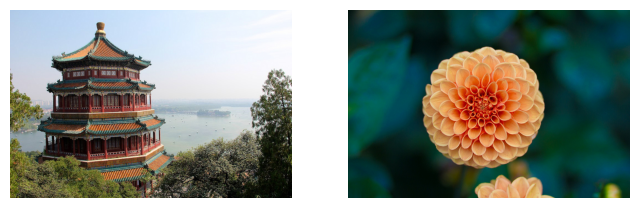

In [ ]:
import matplotlib.pyplot as plt

def plot_image(image):
  plt.imshow(image.permute(1, 2, 0))
  plt.axis('off')

plt.figure(figsize=(8, 4))
for index, image in enumerate(sample_images_permuted):
  plt.subplot(1, 2, index+1)
  plot_image(image)

plt.show()

Center crop the images to small 70×120 images:

In [ ]:
import torchvision
import torchvision.transforms.v2 as T

cropped_images = T.CenterCrop(size=(70, 120))(sample_images_permuted)

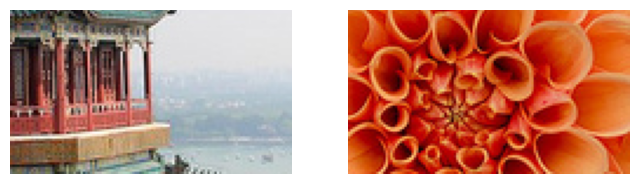

In [ ]:
plt.figure(figsize=(8, 4))
for index, image in enumerate(cropped_images):
  plt.subplot(1, 2, index+1)
  plot_image(image)

plt.show()

Let's create a convolutional layer with 32 filters, each of size 7x7:

In [ ]:
import torch.nn as nn

torch.manual_seed(42)
conv_layer = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=7)
fmaps = conv_layer(cropped_images)

In [ ]:
fmaps.shape

torch.Size([2, 32, 64, 114])

The shape is `[2, 32, 64, 114]`, with width and height of feature maps reduced by 6 because we didn't use zero padding.

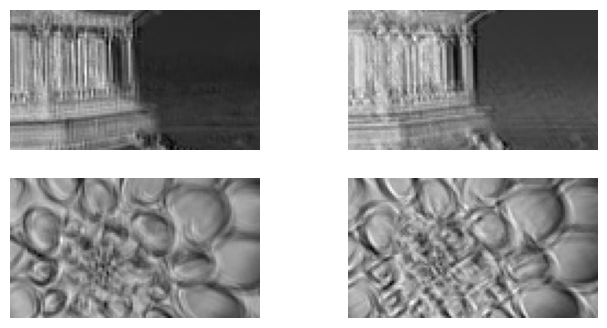

In [ ]:
plt.figure(figsize=(8, 4))
for image_idx in (0, 1):
  for fmap_idx in (0, 1):
    plt.subplot(2, 2, image_idx * 2 + fmap_idx + 1)
    plt.imshow(fmaps[image_idx, fmap_idx].detach(), cmap='grey') # use detach() to receive a new tensor that doesn't require grad (to use imshow)
    plt.axis('off')
plt.show()

Now let's use zero padding:

In [ ]:
conv_layer = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=7,
                       padding='same')
fmaps = conv_layer(cropped_images)

In [ ]:
fmaps.shape

torch.Size([2, 32, 70, 120])

In [ ]:
conv_layer.weight.shape

torch.Size([32, 3, 7, 7])

In [ ]:
conv_layer.bias.shape

torch.Size([32])

## Pooling Layers

### Implementing Pooling Layers with PyTorch

#### Max pooling

In [ ]:
max_pool = nn.MaxPool2d(kernel_size=2)

In [ ]:
output_max = max_pool(cropped_images)

In [ ]:
avg_pool = nn.AvgPool2d(kernel_size=2)

#### Depth-wise pooling

In [ ]:
import torch.nn.functional as F

class DepthMaxPool2(torch.nn.Module):
  def __init__(self, kernel_size, stride=None, padding=0):
    super().__init__()
    self.kernel_size = kernel_size
    self.stride = stride if stride is not None else kernel_size
    self.padding = padding

  def forward(self, inputs):
    batch, channels, height, width = inputs.shape
    Z = inputs.view(batch, channels, height*width)
    Z = Z.permute(0, 2, 1)
    Z = F.max_pool1d(Z, kernel_size=self.kernel_size, stride=self.stride,
                     padding=self.padding)
    Z = Z.permute(0, 2, 1)
    return Z.view(batch, -1, height, width)

#### Global Average Pooling

In [ ]:
global_avg_pool = nn.AdaptiveAvgPool2d(output_size=1)

In [ ]:
output = global_avg_pool(cropped_images)

In [ ]:
output = cropped_images.mean(dim=(2, 3), keepdim=True)

# CNN Architectures

#### Tackling Fashion MNIST With a CNN

In [ ]:
from functools import partial

DefaultConv2d = partial(nn.Conv2d, kernel_size=3, padding='same') # "freeze" or pre-fill a portion of a function's arguments

model = nn.Sequential(
    DefaultConv2d(in_channels=1, out_channels=64, kernel_size=7), nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    DefaultConv2d(in_channels=64, out_channels=128), nn.ReLU(),
    DefaultConv2d(in_channels=128, out_channels=128), nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    DefaultConv2d(in_channels=128, out_channels=256), nn.ReLU(),
    DefaultConv2d(in_channels=256, out_channels=256), nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Flatten(),
    nn.Linear(in_features=2304, out_features=128), nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(in_features=128, out_features=64),nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(in_features=64, out_features=10)
).to(device)

#### Separable Convolutional Layer

In [ ]:
class SeparableConv2d(nn.Module):
  def __init__(self, in_channels, out_channels, kernel_size, stride=1,
               padding=0):
    super().__init__()
    self.depthwise_conv = nn.Conv2d(
        in_channels, in_channels, kernel_size, stride=stride,
        padding=padding, groups=in_channels)
    self.pointwise_conv = nn.Conv2d(
        in_channels, out_channels, kernel_size=1, stride=1, padding=0)

  def forward(self, inputs):
    return self.pointwise_conv(self.depthwise_conv(inputs))

# Implementing a ResNet-34 CNN Using PyTorch

<img src='https://github.com/07-khanh/Hands-On-ML/blob/main/images/resnet.jpg?raw=true'>

<img src='https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/resnet_architecture.png'>

In [ ]:
class ResidualUnit(nn.Module):
  def __init__(self, in_channels, out_channels, stride=1):
    super().__init__()
    DefaultConv2d = partial(
        nn.Conv2d, kernel_size=3, stride=1, padding=1, bias=False)
    self.main_layers = nn.Sequential(
        DefaultConv2d(in_channels, out_channels, stride=stride),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        DefaultConv2d(out_channels, out_channels),
        nn.BatchNorm2d(out_channels),
    )

    if stride > 1:
      self.skip_connection = nn.Sequential(
          DefaultConv2d(in_channels, out_channels, kernel_size=1,
                        stride=stride, padding=0),
          nn.BatchNorm2d(out_channels)
      )
    else:
      self.skip_connection = nn.Identity()

  def forward(self, inputs):
    return F.relu(self.main_layers(inputs) + self.skip_connection(inputs))

In [ ]:
class ResNet34(nn.Module):
  def __init__(self):
    super().__init__()
    layers = [
        nn.Conv2d(in_channels=3, out_channels=64, kernel_size=7, stride=2,
                  padding=3, bias=False),
        nn.BatchNorm2d(num_features=64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
    ]
    prev_filters = 64
    for filters in [64] * 3 + [128] * 4 + [256] * 6 + [512] * 3:
      stride = 1 if filters == prev_filters else 2
      layers.append(ResidualUnit(prev_filters, filters, stride=stride))
      prev_filters = filters
    layers += [
        nn.AdaptiveAvgPool2d(output_size=1),
        nn.Flatten(),
        nn.LazyLinear(out_features=10),
    ]
    self.resnet = nn.Sequential(*layers)

  def forward(self, inputs):
    return self.resnet(inputs)


# Using TorchVision’s Pretrained Models

In [ ]:
weights = torchvision.models.ConvNeXt_Base_Weights.IMAGENET1K_V1
model = torchvision.models.convnext_base(weights=weights).to(device)

Downloading: "https://download.pytorch.org/models/convnext_base-6075fbad.pth" to /root/.cache/torch/hub/checkpoints/convnext_base-6075fbad.pth


100%|██████████| 338M/338M [00:05<00:00, 60.3MB/s]


In [ ]:
torch.hub.get_dir()

'/root/.cache/torch/hub'

In [ ]:
torchvision.models.resnet34

<function torchvision.models.resnet.resnet34(*, weights: Optional[torchvision.models.resnet.ResNet34_Weights] = None, progress: bool = True, **kwargs: Any) -> torchvision.models.resnet.ResNet>

In [ ]:
transforms = weights.transforms()
preprocessed_images = transforms(sample_images_permuted)

In [ ]:
model.eval()
with torch.no_grad():
  y_logits = model(preprocessed_images.to(device))

In [ ]:
y_pred = torch.argmax(y_logits, dim=1)
y_pred

tensor([698, 985])

In [ ]:
class_names = weights.meta['categories']
[class_names[class_id] for class_id in y_pred]

['palace', 'daisy']

In [ ]:
y_top3_logits, y_top3_ids = y_logits.topk(k=3, dim=1)
[[class_names[class_id] for class_id in top3] for top3 in y_top3_ids]

[['palace', 'monastery', 'lakeside'], ['daisy', 'pot', 'ant']]

In [ ]:
y_top3_logits.softmax(dim=1)

tensor([[0.8618, 0.1185, 0.0197],
        [0.8106, 0.0964, 0.0930]])

# Pretrained Models for Transfer Learning

In [ ]:
DefaultFlowers102 = partial(torchvision.datasets.Flowers102, root='datasets',
                            transform=weights.transforms(), download=True)
train_set = DefaultFlowers102(split='train')
val_set = DefaultFlowers102(split='val')
test_set = DefaultFlowers102(split='test')

100%|██████████| 345M/345M [00:11<00:00, 30.9MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.17MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 7.65MB/s]


In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
val_loader = DataLoader(val_set, batch_size=32)
test_loader = DataLoader(test_set, batch_size=32)

In [ ]:
class_names = torchvision.datasets.Flowers102.classes

In [ ]:
[name for name, child in model.named_children()]

['features', 'avgpool', 'classifier']

In [ ]:
model.classifier

Sequential(
  (0): LayerNorm2d((1024,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=1024, out_features=1000, bias=True)
)

In [ ]:
n_classes = 102
model.classifier[2] = nn.Linear(1024, n_classes).to(device)

In [ ]:
for param in model.parameters():
  param.requires_grad = False
for param in model.classifier.parameters():
  param.requires_grad = True


In [ ]:
%pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 15.8 MB/s eta 0:00:00


In [ ]:
import torchmetrics

def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric.update(y_pred, y_batch)
    return metric.compute()

def train(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs):
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(metric.compute().item())
        history["valid_metrics"].append(
            evaluate_tm(model, valid_loader, metric).item())
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")
    return history

In [ ]:
n_epochs = 5
optimizer = torch.optim.AdamW(model.parameters())
xentropy = nn.CrossEntropyLoss()
accuracy = torchmetrics.Accuracy(task='multiclass',
                                 num_classes=n_classes).to(device)
history = train(model, optimizer, xentropy, accuracy, train_loader, val_loader,
                n_epochs)

Epoch 1/5, train loss: 4.2843, train metric: 0.1480, valid metric: 0.5696
Epoch 2/5, train loss: 3.0015, train metric: 0.7196, valid metric: 0.7696
Epoch 3/5, train loss: 2.0661, train metric: 0.8392, valid metric: 0.8461
Epoch 4/5, train loss: 1.3710, train metric: 0.9029, valid metric: 0.8618
Epoch 5/5, train loss: 0.9468, train metric: 0.9422, valid metric: 0.8706


In [ ]:
history = train(model, optimizer, xentropy, accuracy, train_loader, val_loader,
                n_epochs)

Epoch 1/5, train loss: 0.6861, train metric: 0.9627, valid metric: 0.8765
Epoch 2/5, train loss: 0.5003, train metric: 0.9784, valid metric: 0.8863
Epoch 3/5, train loss: 0.3925, train metric: 0.9804, valid metric: 0.8814
Epoch 4/5, train loss: 0.3139, train metric: 0.9873, valid metric: 0.8941
Epoch 5/5, train loss: 0.2516, train metric: 0.9873, valid metric: 0.8912


In [ ]:
for param in model.parameters():
  param.requires_grad = True

In [ ]:
history = train(model, optimizer, xentropy, accuracy, train_loader, val_loader,
                n_epochs)

Epoch 1/5, train loss: 0.7352, train metric: 0.8010, valid metric: 0.7775
Epoch 2/5, train loss: 0.3090, train metric: 0.9147, valid metric: 0.8676
Epoch 3/5, train loss: 0.0976, train metric: 0.9716, valid metric: 0.8755
Epoch 4/5, train loss: 0.0981, train metric: 0.9735, valid metric: 0.8186
Epoch 5/5, train loss: 0.1001, train metric: 0.9755, valid metric: 0.8716


In [ ]:
import torchvision.transforms.v2 as T

transform = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=30),
    T.RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0)),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Classification and Localization

---

Localization in computer vision is the process of identifying the exact position of objects within an image or video, typically by drawing a bounding box around them.

Localizing an object in a picture can be expressed as a regression task, as discussed: to predict a bounding box around the object, a common approach is
to predict the location of the bounding box’s center, as well as its width and height (alternatively, you could predict the horizontal and vertical coordinates of the object’s upper-left and lower-right corners). This means we have four numbers to predict.

---

---

Let's adds a localization head (a dense output layer with 4 units) to a given base model, such as our ConvNeXt model

---

In [ ]:
class FlowerLocator(nn.Module):
  def __init__(self, base_model):
    super().__init__()
    self.base_model = base_model
    self.localization_head = nn.Sequential(
        nn.Flatten(),
        nn.Linear(self.base_model.classifier[2].in_features, 4))

  def forward(self, X):
    features = self.base_model.features(X)
    pool = self.base_model.avgpool(features)
    y_pred_logits = self.base_model.classifier(pool)
    y_pred_bbox = self.localization_head(pool)
    return y_pred_logits, y_pred_bbox

In [ ]:
torch.manual_seed(42)
locator_model = FlowerLocator(model).to(device)

In [ ]:
preproc_images = torch.randn(2, 3, 224, 224) # a batch of preprocessed images
y_pred_logits, y_pred_bbox = locator_model(preproc_images)

In [ ]:
y_pred_bbox

tensor([[-0.1705, -0.1484, -0.0164, -0.0337],
        [-0.1652, -0.1618, -0.0210, -0.0267]], grad_fn=<AddmmBackward0>)

---

We can also use `torchvision.tv_tensors.BoundingBoxes` to make creating bouding boxes more convenient.

Let's create a bounding box for the largest flower in the first image of the Flowers102 training set.

---

In [ ]:
import torchvision.tv_tensors

bbox = torchvision.tv_tensors.BoundingBoxes(
    [[377, 199, 248, 262]], # center x=377, center y=199, width=248, height=262
    format='CXCYWH', # the numbers above represent center x, center y, width, and height.
    canvas_size=(500, 754) # the original image's height and width
)

---

The `BoundingBoxes` class is a subclass of `TVTensor`, which is a subclass of `torch.Tensor`, so you can treat bounding boxes exactly like regular tensors, with extra features. Most importantly, you can transform bounding boxes using TorchVision’s transforms API v2.

---

In [ ]:
transform(bbox)

BoundingBoxes([[ 90,  91, 120, 154]], format=BoundingBoxFormat.CXCYWH, canvas_size=(224, 224), clamping_mode=soft)

---

You can pass a nested data structure to a transform and the output will have the
same structure, except with all the images and bounding boxes transformed.

---

In [ ]:
torch.manual_seed(42)
first_image = torchvision.datasets.Flowers102(root='datasets', split='train')[0][0]
preproc_image, preproc_target = transform(
    (first_image, {'label': 0, 'bbox': bbox})
)
preproc_bbox = preproc_target['bbox']

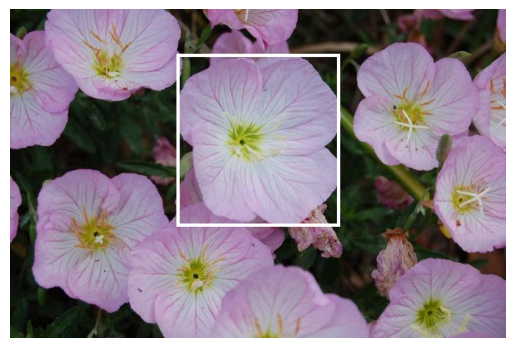

In [ ]:
def get_image_with_bbox(image, bbox, width=5, color='white'):
  bbox_xyxy = torchvision.ops.box_convert(bbox, 'cxcywh', 'xyxy')
  return torchvision.utils.draw_bounding_boxes(
      image, bbox_xyxy, width=width, colors=color)

first_image_ts = T.ToImage()(first_image)
image_with_bbox = get_image_with_bbox(first_image_ts, bbox)
plot_image(image_with_bbox)
plt.show()

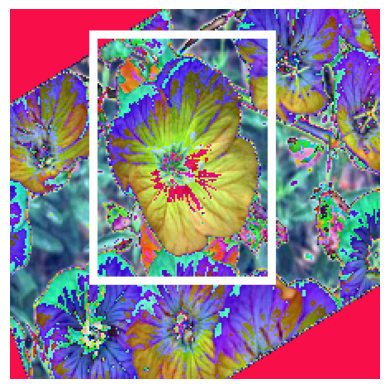

In [ ]:
pre_image_with_bbox = get_image_with_bbox(preproc_image, preproc_bbox)
plot_image(pre_image_with_bbox)
plt.show()

---

Let's look at the transformed image and bounding box:

---

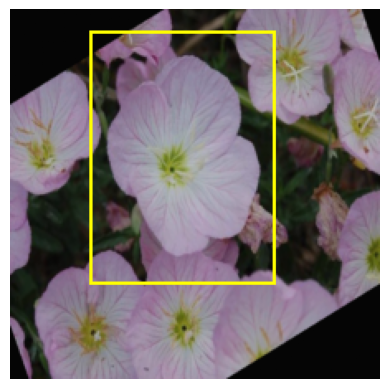

In [ ]:
def denormalize(image, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]):
  return (image * torch.tensor(std).view(-1, 1, 1) +
          torch.tensor(mean).view(-1, 1, 1))

image_with_bbox2 = get_image_with_bbox(
    denormalize(preproc_image), preproc_bbox, width=2, color='yellow'
)
plot_image(image_with_bbox2)
plt.show()

---

Below we can see the transformed bounding box (in yellow), which fits the whole transformed region (in white) rather than the transformed flower. This is why the transformed bounding box ends up being a bit too big. Try running this cell multiple times with different random seeds to see how larger rotations lead to inaccurate bounding boxes:

---

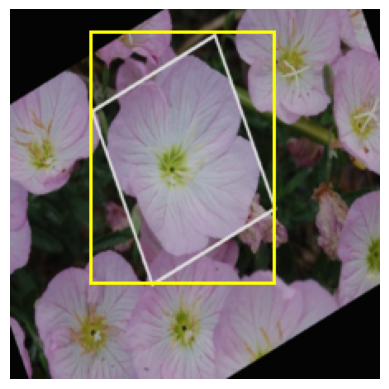

In [ ]:
torch.manual_seed(42)

preproc_image2, preproc_target2 = transform(
    (image_with_bbox, {'label': 0, 'bbox': bbox})
)
image_and_bbox3 = get_image_with_bbox(
    denormalize(preproc_image2), preproc_target2['bbox'], width=2,
    color='yellow')
plot_image(image_and_bbox3)
plt.show()

---

Now let's create a custom dataset to extend the Flowers102 with bounding boxes. We only have two bounding boxes here, but of course with more time and effort this could be extended to the whole dataset, which would allow us to train the FlowerLocator model:

---

In [ ]:
bboxes = [
    torchvision.tv_tensors.BoundingBoxes(
        [[377, 199, 248, 262]],
        format="CXCYWH",
        canvas_size=(500, 754)
    ),
    torchvision.tv_tensors.BoundingBoxes(
        [[314, 248, 437, 445]],
        format="CXCYWH",
        canvas_size=(500, 624)
    )
]

In [ ]:
class FlowersWithBBox(torch.utils.data.Dataset):
  def __init__(self, root, bboxes, transform=None, split='train'):
    self.image_dataset = torchvision.datasets.Flowers102(root=root, split=split)
    self.bboxes = bboxes
    self.transform = transform

  def __len__(self):
    return len(self.bboxes)

  def __getitem__(self, index):
    raw_image, label = self.image_dataset[index]
    image = torchvision.tv_tensors.Image(raw_image)
    bbox = self.bboxes[index]
    preproc_image, preproc_bbox = self.transform(image, bbox)
    return preproc_image, {'label': label, 'bbox': preproc_bbox}

train_set_with_bboxes = FlowersWithBBox('datasets', bboxes, transform=transform)

In [ ]:
train_loader_with_bboxes = DataLoader(train_set_with_bboxes, batch_size=2)
for images, label_and_bbox in train_loader_with_bboxes:
  label = label_and_bbox['label']
  bbox = label_and_bbox['bbox']
  # we could train the model here

tensor([0, 0])


---

We can use the **IoU** loss to train the model for predicting bounding boxes.

<img src='https://cdn.learnopencv.com/wp-content/uploads/2023/02/04091257/iou_and_iou_loss.png' width=400>

However, IoU has a limitation which is it becomes zero when there is no overlap between the 2 boxes, regardless of the distance between them and their shape.

**Generalized IoU** fixes that flaw by incorporating extra information.

<img src='https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRFdAOVrKS5eOi2sEY2AbAhcMqHnTgyrSWog7ZyAbwTgnSeoTvrWd__fe8&s=10' width=400>

Another important variant of the IoU is the **Complete IoU** (CIoU). It considers three geometric factors:
- the IoU (the more overlap, the better)
- the distance between the centers of the 2 boxes (the closer,the better), normalized by the length of the diagonal of S
- the similarity between the aspect ratios of the 2 boxes (the closer, the better).

<img src='https://images.openai.com/static-rsc-4/g_L_4zubcUUNZ__pNkSWXfnuLeW8EsWbY0hEArx-Q6Bjx3WFihaPChD7YYl2S3-M_IkpQSGvcjlsuL4wiY7IalQzSwws2LkroxIrePSZb3GdNZhsW7tXbnrRYUhgIlSjIAG25K2EI80r-SPuM8jSMpbdlA0pOOHEU_OA9PrNgs7RtzMCl-AUbrY4mf3zNnHl?purpose=fullsize' width=400>

---

# Object Detection

---

The task of classifying and localizing multiple objects in an image is called object
detection.

---

In [ ]:
%pip install -q ultralytics

In [ ]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
model = YOLO('yolov9m.pt')
images = ["https://homl.info/soccer.jpg", "https://homl.info/traffic.jpg"]
results = model(images)


0: 640x640 5 persons, 2 sports balls, 46.5ms
1: 640x640 3 persons, 7 cars, 1 motorcycle, 11 trucks, 46.5ms
Speed: 36.9ms preprocess, 46.5ms inference, 19.3ms postprocess per image at shape (1, 3, 640, 640)


In [ ]:
results[0].summary()

[{'name': 'sports ball',
  'class': 32,
  'confidence': 0.96214,
  'box': {'x1': 245.3573, 'y1': 286.03003, 'x2': 300.62506, 'y2': 343.57184}},
 {'name': 'person',
  'class': 0,
  'confidence': 0.93886,
  'box': {'x1': 380.47516, 'y1': 52.46332, 'x2': 548.28998, 'y2': 408.30408}},
 {'name': 'person',
  'class': 0,
  'confidence': 0.93407,
  'box': {'x1': 234.47823, 'y1': 31.53569, 'x2': 365.06073, 'y2': 400.27789}},
 {'name': 'person',
  'class': 0,
  'confidence': 0.93391,
  'box': {'x1': 85.80923, 'y1': 19.24835, 'x2': 247.10779, 'y2': 406.453}},
 {'name': 'person',
  'class': 0,
  'confidence': 0.82737,
  'box': {'x1': 41.21783, 'y1': 74.47363, 'x2': 175.22485, 'y2': 399.32819}},
 {'name': 'person',
  'class': 0,
  'confidence': 0.40399,
  'box': {'x1': 613.49731, 'y1': 372.65881, 'x2': 639.71973, 'y2': 419.1228}},
 {'name': 'sports ball',
  'class': 32,
  'confidence': 0.33764,
  'box': {'x1': 23.80591, 'y1': 337.59879, 'x2': 46.33569, 'y2': 346.89529}}]

In [ ]:
annotated_soccer_bgr = results[0].plot()

array([[[ 13,  13,   7],
        [ 11,  11,   5],
        [  9,  11,   5],
        ...,
        [  0,  25,   7],
        [  4,  29,  15],
        [  0,  14,   1]],

       [[  7,   7,   1],
        [  4,   6,   0],
        [  5,   7,   1],
        ...,
        [  1,  35,  18],
        [  0,  18,   4],
        [  3,  21,   8]],

       [[  4,   6,   0],
        [  3,   5,   0],
        [  4,   7,   0],
        ...,
        [ 33,  62,  47],
        [  7,  24,  13],
        [  4,  18,   7]],

       ...,

       [[ 19, 168, 148],
        [ 41, 183, 164],
        [ 51, 179, 162],
        ...,
        [108,  33,  31],
        [255,  42,   4],
        [255,  42,   4]],

       [[ 33, 184, 164],
        [ 54, 198, 179],
        [ 73, 202, 187],
        ...,
        [255,  42,   4],
        [255,  42,   4],
        [255,  42,   4]],

       [[ 26, 179, 158],
        [ 51, 198, 178],
        [ 80, 212, 196],
        ...,
        [255,  42,   4],
        [255,  42,   4],
        [255,  42,   4]]], dtype=uint8)
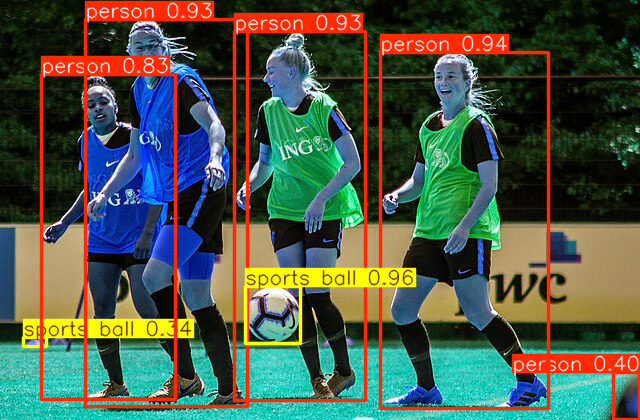

In [ ]:
annotated_soccer_bgr

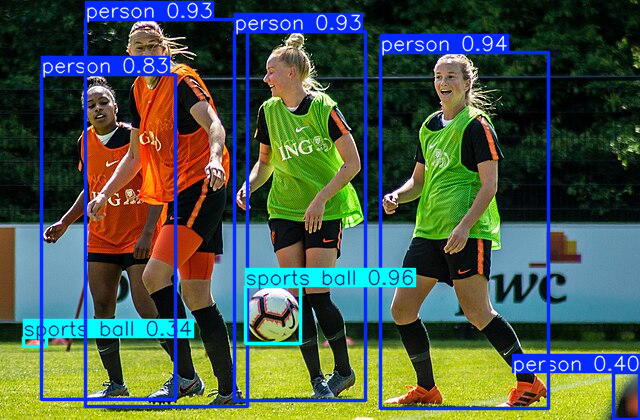

In [ ]:
import cv2
import PIL
annotated_soccer_rgb = cv2.cvtColor(annotated_soccer_bgr, cv2.COLOR_BGR2RGB)
PIL.Image.fromarray(annotated_soccer_rgb)

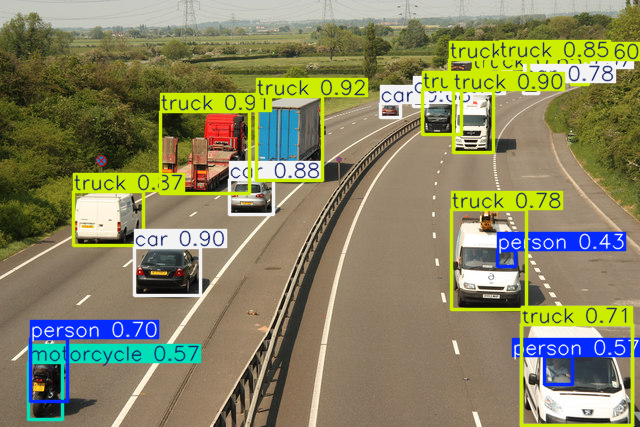

In [ ]:
annotated_traffic_bgr = results[1].plot()
annotated_traffic_rgb = cv2.cvtColor(annotated_traffic_bgr, cv2.COLOR_BGR2RGB)
PIL.Image.fromarray(annotated_traffic_rgb)

# Object Tracking

In [ ]:
my_video = "https://homl.info/cars.mp4"
results = model.track(source=my_video, stream=True, save=True)
for frame_result in results:
  summary = frame_result.summary()
  track_ids = [obj['track_id'] for obj in summary]
  print("Track ids:", track_ids)

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 370ms
Prepared 1 package in 51ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


video 1/1 (frame 1/243) /content/cars.mp4: 384x640 7 cars, 83.0ms
Track ids: [1, 2, 3, 4, 5, 6, 7]
video 1/1 (frame 2/243) /content/cars.mp4: 384x640 7 cars, 45.8ms
Track ids: [1, 2, 3, 4, 5, 6, 7]
video 1/1 (frame 3/243) /content/cars.mp4: 384x640 7 cars, 45.8ms
Track ids: [1, 2, 3, 4, 5, 6, 7]
video 1/1 (frame 4/243) /content/cars.mp4: 384x640 7 cars, 45.8ms
Track ids: [1, 2, 3, 4, 5, 6, 7]
video 1/1 (frame 5/243) /content/cars.mp4: 384x640 7 cars, 45.8ms
Track ids: [1, 2, 3, 4, 5, 6, 7]
video 1/1 (frame 6/243) /content/cars.mp4: 384x640 7 cars, 1 truck, 32.6ms
Track ids: [1, 2, 3, 4, 5, 6, 7, 8]
video 1/1 (frame 7/243) /content/car

# Semantic Segmentation

# Exercise

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms.v2 as T
from torch.utils.data import DataLoader
import os
from PIL import Image
import time
from torch.optim import lr_scheduler
from tempfile import TemporaryDirectory

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
!unzip -q /content/drive/MyDrive/hymenoptera_data.zip -d /content/my_dataset

In [7]:
data_dir = '/content/my_dataset/hymenoptera_data'

data_transform = {
    'train': T.Compose([
        T.RandomResizedCrop(224),
        T.RandomHorizontalFlip(),
        T.ToImage(),
        T.ToDtype(torch.float32, scale=True),
        T.Normalize([0.485, 0.456, 0.406],[0.229, 0.224, 0.225])
    ]),
    'val': T.Compose([
        T.Resize(256),
        T.CenterCrop(224),
        T.ToTensor(),
        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
}

/usr/local/lib/python3.13/dist-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


We use ImageFolder as a data loader for this image dataset, with this specific compatible arrangement.

In [8]:
image_dataset = {x: torchvision.datasets.ImageFolder(os.path.join(data_dir, x),
                                                     transform=data_transform[x])
                for x in ['train', 'val']}
data_loader = {x: DataLoader(image_dataset[x], batch_size=4, shuffle=True)
                for x in ['train', 'val']}

In [9]:
dataset_sizes = {x: len(image_dataset[x]) for x in ['train', 'val']}
class_names = image_dataset['train'].classes

In [10]:
dataset_sizes

{'train': 244, 'val': 153}

In [11]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(device)

cpu


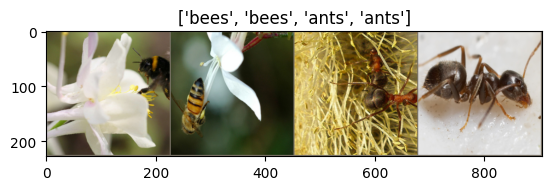

In [12]:
def imshow(inp, title=None):
  inp = inp.numpy().transpose(1, 2, 0)
  mean = np.array([0.485, 0.456, 0.406])
  std = np.array([0.229, 0.224, 0.225])
  inp = inp * std + mean
  inp = np.clip(inp, 0, 1)
  plt.imshow(inp)
  if title is not None:
    plt.title(title)
  plt.pause(0.001)

inputs, classes = next(iter(data_loader['train'])) # [B, C, H, W]
out = torchvision.utils.make_grid(inputs) # [B, C, H, W] -> [C, H + 2P, B*W + 2P]
imshow(out, title=[class_names[x] for x in classes])


In [13]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
  since = time.time()

  # Create temp dir to save checkpoints
  with TemporaryDirectory() as tempdir:
    best_model_params_path = os.path.join(tempdir, 'best_model_params.pt')

    torch.save(model.state_dict(), best_model_params_path)
    best_acc = 0.0

    for epoch in range(num_epochs):
      print(f'Epoch {epoch}/{num_epochs-1}')
      print('-'*10)

      # Each epoch has train and val phase
      for phase in ['train', 'val']:
        if phase == 'train':
          model.train()
        else:
          model.eval()

        running_loss = 0.0
        running_corrects = 0

        for X, y in data_loader[phase]:
          X, y = X.to(device), y.to(device)

          optimizer.zero_grad()

          with torch.set_grad_enabled(phase == 'train'):
            logits = model(X)
            _, preds = torch.max(logits, dim=1)
            loss = criterion(logits, y)

            if phase == 'train':
              loss.backward()
              optimizer.step()

          running_loss += loss.item() * X.size(0)
          running_corrects += torch.sum(preds == y.data)

        if phase == 'train':
          scheduler.step()

        epoch_loss = running_loss / dataset_sizes[phase]
        epoch_acc = running_corrects.double() / dataset_sizes[phase]

        print(f'{phase} loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

        if phase == 'val' and epoch_acc > best_acc:
          torch.save(model.state_dict(), best_model_params_path)

      print()

    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best accuracy: {best_acc:.4f}')

    model.load_state_dict(torch.load(best_model_params_path, weights_only=True))

  return model


In [14]:
def visualize_model(model, num_images=6):
  was_training = model.training
  model.eval()
  images_so_far = 0
  fig = plt.figure()

  with torch.no_grad():
    for i, (X, y) in enumerate(data_loader['val']):
      X, y = X.to(device), y.to(device)

      logits = model(X)
      _, preds = torch.max(logits, dim=1)

      for j in range(X.size(0)):
        ax = plt.subplot(num_images // 2, 2, images_so_far)
        ax.axis('off')
        ax.set_title(f'predicted: {class_names[preds[j]]}')
        imshow(X.cpu().data[j])

        if images_so_far == num_images:
          model.train(was_training)
          return
      model.train(was_training)

In [20]:
model_ft = torchvision.models.resnet18(weights='IMAGENET1K_V1')
num_ftrs = model_ft.fc.in_features
model_ft.fc = nn.Linear(num_ftrs, 2)
model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()
optimizer_ft = torch.optim.SGD(model_ft.parameters(), lr=1e-3, momentum=0.9)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

In [24]:
model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler, num_epochs=25)

AttributeError: 'ResNet' object has no attribute 'classifier'